# 03 - Feature selection
Filter, wrapper and embedded methods for the churn and spend models. Everything is **fitted on TRAIN only**; TEST is used only in the final comparison. Skewed features are log1p-transformed and the segment is one-hot encoded (encoder fitted on TRAIN).

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import config
import feature_selection as fs

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

train = pd.read_parquet(config.TRAIN_TABLE_PARQUET)
test = pd.read_parquet(config.TEST_TABLE_PARQUET)

encoder = fs.fit_segment_encoder(train)
X = fs.make_model_matrix(train, encoder)
y_churn = fs.churn_target(train)
y_spend = fs.spend_target(train)
print(X.shape)
list(X.columns)

(3465, 16)


['recency',
 'frequency',
 'monetary',
 'avg_order_value',
 'avg_gap_days',
 'tenure_days',
 'unique_products',
 'return_rate',
 'spend_trend',
 'purchase_regularity',
 'is_uk',
 'is_single_order',
 'seg_At-Risk',
 'seg_Champions',
 'seg_Loyal',
 'seg_One-off buyers']

## 1. Correlation heatmap

,feature_1,feature_2,r
0,recency,seg_At-Risk,0.829
1,frequency,monetary,0.820


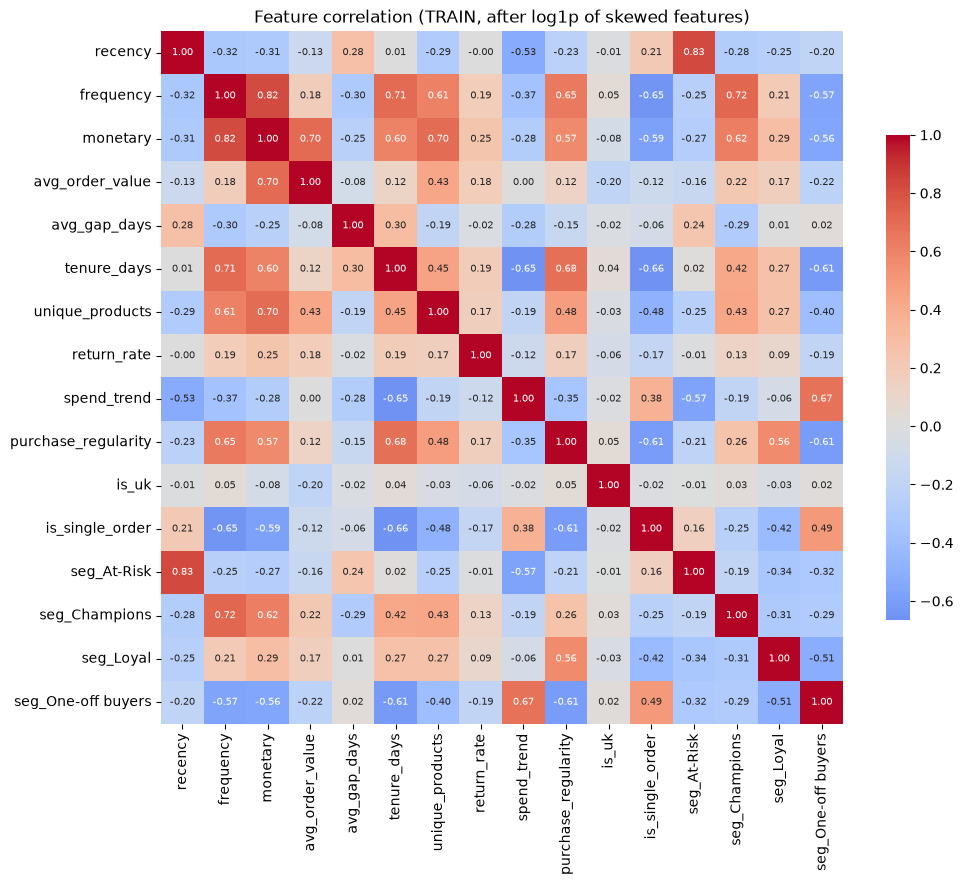

In [2]:
fig, high_pairs = fs.plot_correlation(X)
high_pairs.to_csv(config.TABLES_DIR / 'high_correlation_pairs.csv', index=False)
high_pairs

**Highly correlated pairs (|r| > 0.8):** `recency` and `seg_At-Risk` (r = 0.83), because the At-Risk segment is basically 'high recency'; and `frequency` and `monetary` (r = 0.82), because customers who order more also spend more. Each pair carries mostly the same information twice.

## 2-4. Filter, wrapper and embedded scores

In [3]:
filters = fs.filter_scores(X, y_churn, y_spend)
rfe_rank = fs.rfe_logistic(X, y_churn)
embedded = fs.embedded_scores(X, y_churn, y_spend)

all_scores = filters.join(rfe_rank).join(embedded)
all_scores.to_csv(config.TABLES_DIR / 'feature_selection_scores.csv')
all_scores.round(3)

,mi_churn,anova_f_churn,mi_spend,f_reg_spend,rfe_rank,rf_importance_churn,rf_importance_spend,l1_coef_churn,lasso_coef_spend
recency,0.029,231.211,0.068,281.286,1,0.095,0.085,0.227,-0.349
frequency,0.116,909.646,0.221,1442.745,1,0.128,0.086,-0.975,-0.000
monetary,0.089,651.206,0.305,1395.233,1,0.132,0.366,-0.110,1.926
avg_order_value,0.018,52.929,0.109,236.468,1,0.074,0.074,0.000,-0.686
avg_gap_days,0.034,148.109,0.109,180.170,1,0.088,0.066,0.170,-0.159
tenure_days,0.048,292.023,0.074,471.213,1,0.102,0.062,-0.186,0.081
unique_products,0.057,335.949,0.124,609.025,7,0.081,0.072,0.000,-0.031
return_rate,0.075,32.584,0.114,76.753,6,0.029,0.017,-0.020,0.088
spend_trend,0.047,17.496,0.085,51.197,1,0.058,0.044,-0.182,0.050
purchase_regularity,0.084,293.914,0.165,505.438,1,0.110,0.075,0.145,-0.050


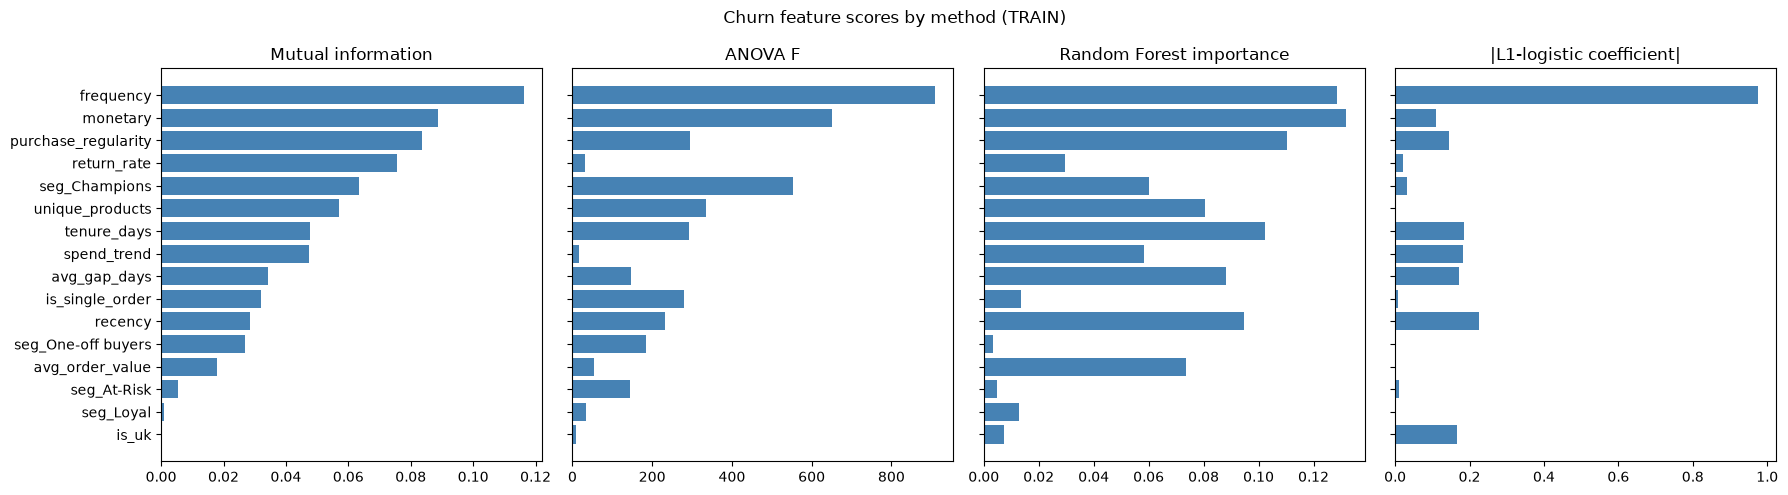

In [4]:
fs.plot_method_scores(filters, embedded);

**What the scores show:** `frequency`, `monetary`, `purchase_regularity` and `tenure_days` score high in almost every churn method. `recency` has a large ANOVA F and RF importance but a low mutual information (0.029). `is_uk` is near zero everywhere. The segment columns are mostly low, except `seg_Champions`. L1-logistic is not very selective here: it keeps 14 of 16 features, only zeroing `avg_order_value`, `unique_products` (and `seg_One-off buyers`).

## 5. Which features each method keeps
1 = kept. Ranking methods keep their top 8; RFE keeps 8; L1 / Lasso keep every non-zero coefficient.

In [5]:
selection = fs.selection_table(filters, rfe_rank, embedded)
selection.to_csv(config.TABLES_DIR / 'feature_selection_comparison.csv')
selection

,MI (churn),ANOVA F (churn),RFE-LogReg (churn),RF importance (churn),L1-logistic (churn),MI (spend),f_regression (spend),RF importance (spend),Lasso (spend),votes_churn,votes_spend
recency,0,1,1,1,1,0,0,1,1,4,2
frequency,1,1,1,1,1,1,1,1,0,5,3
monetary,1,1,1,1,1,1,1,1,1,5,4
avg_order_value,0,0,1,1,0,1,0,1,1,2,3
avg_gap_days,0,0,1,1,1,1,0,1,1,3,3
tenure_days,1,1,1,1,1,0,1,1,1,5,3
unique_products,1,1,0,1,0,1,1,1,1,3,4
return_rate,1,0,0,0,1,1,0,0,1,2,2
spend_trend,1,0,1,0,1,0,0,0,1,3,1
purchase_regularity,1,1,1,1,1,1,1,1,1,5,4


In [6]:
churn_features = fs.choose_features(selection, filters, 'votes_churn', 'mi_churn')
spend_features = fs.choose_features(selection, filters, 'votes_spend', 'mi_spend')
print('Churn features:', churn_features)
print('Spend features:', spend_features)

Churn features: ['frequency', 'monetary', 'purchase_regularity', 'tenure_days', 'recency', 'seg_Champions', 'unique_products', 'spend_trend']
Spend features: ['monetary', 'purchase_regularity', 'unique_products', 'frequency', 'seg_Champions', 'avg_gap_days', 'avg_order_value', 'tenure_days']


**Chosen churn features (8):** frequency, monetary, purchase_regularity, tenure_days, recency (each kept by 4-5 of the 5 churn methods), then seg_Champions, unique_products and spend_trend (3 votes each; ties broken by mutual information). `avg_gap_days` also had 3 votes but lower MI, so it was left out.

**Chosen spend features (8):** monetary, purchase_regularity, unique_products, frequency, seg_Champions, avg_gap_days, avg_order_value, tenure_days. These will be checked properly in the spend phase.

## 6. All features vs selected subset (Logistic Regression, TEST)
Same simple model (scaled Logistic Regression, threshold 0.5), trained on TRAIN, scored on TEST. The recency-only rule is the reference bar.

In [7]:
comparison = fs.compare_on_test(train, test, encoder, churn_features)
comparison.to_csv(config.TABLES_DIR / 'feature_subset_comparison.csv')
comparison

,n_features,precision,recall,f1,roc_auc,pr_auc,mean_predicted_prob
"Recency only (baseline, threshold = train median)",1,0.607,0.714,0.657,0.660,0.642,NaN
LogReg - all features,16,0.669,0.749,0.707,0.763,0.745,0.526
LogReg - selected features,8,0.655,0.802,0.721,0.764,0.742,0.548


**Result:** The reduced set (8 features) performs **about the same** as all 16 features: ROC-AUC 0.764 vs 0.763, PR-AUC 0.742 vs 0.745, F1 0.721 vs 0.707 (the F1 gain comes from higher recall at the 0.5 threshold, not better ranking). Both clearly beat the recency-only baseline (ROC-AUC 0.660, F1 0.657). Mean predicted churn probability on test is 0.53-0.55 while the actual test churn rate is 0.50, so probabilities are a little high, as expected from the 0.62 train churn rate.

### Does the segment add anything beyond RFM?

In [8]:
ablation = fs.segment_ablation(train, test, encoder)
ablation.to_csv(config.TABLES_DIR / 'segment_ablation.csv')
ablation

,n_features,precision,recall,f1,roc_auc,pr_auc,mean_predicted_prob
Segment only,4,0.612,0.898,0.728,0.724,0.659,0.566
RFM only,3,0.664,0.771,0.713,0.760,0.738,0.545
RFM + segment,7,0.657,0.789,0.717,0.760,0.738,0.543
All features without segment,12,0.671,0.747,0.707,0.763,0.745,0.526
All features with segment,16,0.669,0.749,0.707,0.763,0.745,0.526


**Segment honestly adds little.** RFM alone reaches ROC-AUC 0.760; adding the four segment columns gives 0.760 too. All features without the segment give 0.763 vs 0.763 with it. The segment is built from the same RFM values, so a model that already sees RFM learns nothing new from it. It is still useful for explaining customers in the app and report, and seg_Champions stays in the churn list only because of the vote rule.

## 7. Save the chosen feature lists

In [9]:
fs.save_selected_features(churn_features, spend_features)

{'churn': ['frequency',
  'monetary',
  'purchase_regularity',
  'tenure_days',
  'recency',
  'seg_Champions',
  'unique_products',
  'spend_trend'],
 'spend': ['monetary',
  'purchase_regularity',
  'unique_products',
  'frequency',
  'seg_Champions',
  'avg_gap_days',
  'avg_order_value',
  'tenure_days'],
 'log1p_features': ['frequency',
  'monetary',
  'avg_order_value',
  'unique_products',
  'purchase_regularity'],
 'segment_column': 'segment_name'}